In [24]:
import numpy as np 
import pandas as pd
from tqdm import tqdm 
from sklearn.metrics import root_mean_squared_error
from statsmodels.graphics.tsaplots import plot_acf,plot_pacf
import matplotlib.pyplot as plt
import statsmodels.api as sn
from statsmodels.tsa.stattools import adfuller
from statsmodels.tsa.arima.model import ARIMA
from pmdarima.arima import auto_arima

In [25]:
df=pd.read_csv("F:\MACHINE LEARNING\SOMETHING\Datasets\AusGas.csv")
df.head()

,Month,GasProd
0,Jan-1956,1709
1,Feb-1956,1646
2,Mar-1956,1794
3,Apr-1956,1878
4,May-1956,2173


In [26]:
y=df.GasProd
y_train=y[:-20]
y_test=y[-20:]


In [36]:
model=auto_arima(m=12,trace=True,suppress_warnings=True,error_action='ignore',y=y_train)


Performing stepwise search to minimize aic
 ARIMA(2,1,2)(1,0,1)[12] intercept   : AIC=inf, Time=3.44 sec
 ARIMA(0,1,0)(0,0,0)[12] intercept   : AIC=8468.760, Time=0.02 sec
 ARIMA(1,1,0)(1,0,0)[12] intercept   : AIC=8041.227, Time=1.23 sec
 ARIMA(0,1,1)(0,0,1)[12] intercept   : AIC=8254.264, Time=0.76 sec
 ARIMA(0,1,0)(0,0,0)[12]             : AIC=8467.312, Time=0.03 sec
 ARIMA(1,1,0)(0,0,0)[12] intercept   : AIC=8426.167, Time=0.04 sec
 ARIMA(1,1,0)(2,0,0)[12] intercept   : AIC=inf, Time=3.19 sec
 ARIMA(1,1,0)(1,0,1)[12] intercept   : AIC=8002.376, Time=1.77 sec
 ARIMA(1,1,0)(0,0,1)[12] intercept   : AIC=8253.284, Time=0.70 sec
 ARIMA(1,1,0)(2,0,1)[12] intercept   : AIC=8020.385, Time=6.08 sec
 ARIMA(1,1,0)(1,0,2)[12] intercept   : AIC=8019.311, Time=5.07 sec
 ARIMA(1,1,0)(0,0,2)[12] intercept   : AIC=8168.817, Time=2.46 sec
 ARIMA(1,1,0)(2,0,2)[12] intercept   : AIC=inf, Time=nan sec
 ARIMA(0,1,0)(1,0,1)[12] intercept   : AIC=8045.114, Time=2.23 sec
 ARIMA(2,1,0)(1,0,1)[12] intercept 

In [32]:
forecast=model.predict(n_periods=len(y_test))
forecast=pd.DataFrame(forecast,index=y_test.index,columns=['Prediction'])
forecast

,Prediction
456,40713.525951
457,40826.032232
458,38318.591453
459,44889.553859
460,53153.044998
461,58727.666471
462,59672.653447
463,58705.747932
464,54460.432789
465,50137.730722


In [33]:
len(y_test)

20

In [34]:
rms=root_mean_squared_error(y_test,forecast)
rms

3664.429788116689

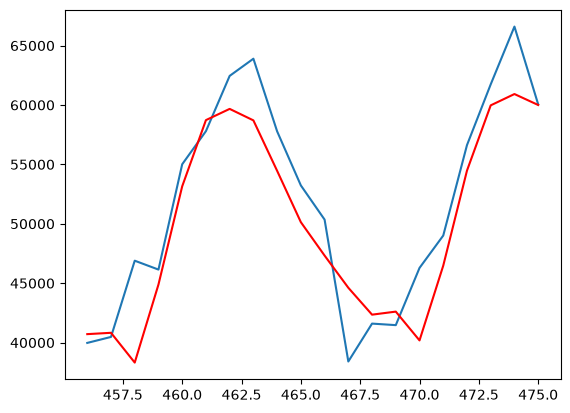

In [35]:
plt.plot(y_test)
plt.plot(forecast,color='red')
plt.show()

# with pipeline

In [39]:
from pmdarima.pipeline import Pipeline
from pmdarima.preprocessing import BoxCoxEndogTransformer
import pmdarima as pm

In [40]:
pipeline=Pipeline([
    ('boxcox', BoxCoxEndogTransformer()),
    ('model', pm.AutoARIMA(seasonal=True,suppress_warnings=True,m=12,error_action='ignore'))
     ])
pipeline.fit(y_train)


,steps,"[('boxcox', ...), ('model', ...)]"
Name,Type,Value
n_samples_,int,456
steps_,list,"[('boxcox', BoxCoxEndogTransformer()), ('model', AutoARIMA(err...ignore', m=12))]"
x_feats_,NoneType,None


In [45]:
forecast=pipeline.predict(n_periods=len(y_test))
rsm=root_mean_squared_error(y_test,forecast)
rsm

2720.925928241131

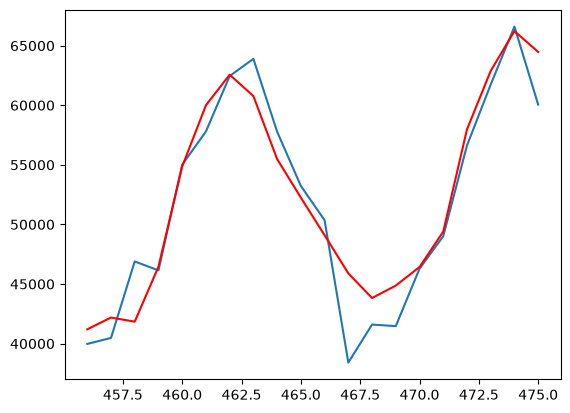

In [47]:
forecast=pd.DataFrame(forecast,index=y_test.index,columns=['Prediction'])
plt.plot(y_test)
plt.plot(forecast,color='red')
plt.show()